In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't scikit be saved outside of the current session

Predicted Popularity: 33.10739139819724


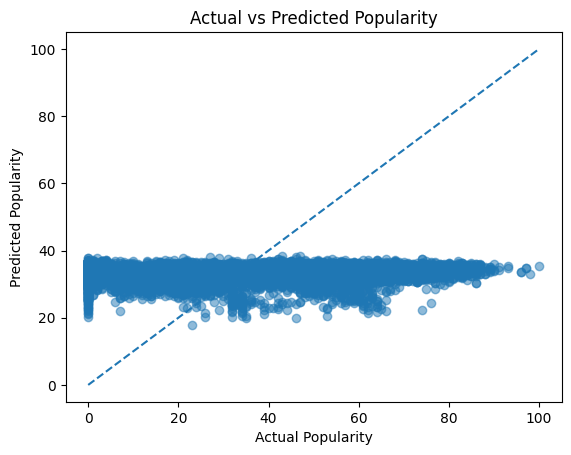

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split

# Load dataset

df = pd.read_csv("/kaggle/input/datasets/maharshipandya/-spotify-tracks-dataset/dataset.csv")

# Select columns and clean data

df = df[['tempo', 'energy', 'danceability', 'loudness','popularity']].dropna()

# Define features and target

X = df[['tempo', 'energy', 'danceability','loudness']]

y = df['popularity']


# Split data

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2)


# Train model
model = LinearRegression()

model.fit(X_train, y_train)


#trained model to predict on test data
y_pred = model.predict(X_test)

# Predict for a new song

new_song = pd.DataFrame([[120, 0.80, 0.75,-7]],
                        columns=['tempo', 'energy', 'danceability','loudness'])

prediction = model.predict(new_song)

print("Predicted Popularity:", prediction[0])


# Plot
plt.scatter(y_test, y_pred, alpha=0.5)

plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], linestyle='--')

plt.xlabel("Actual Popularity")

plt.ylabel("Predicted Popularity")

plt.title("Actual vs Predicted Popularity")

plt.show()